# 04 · Price model and SHAP explanations

**Question:** what drives the price per m² of a Paris apartment, and which areas sell below what their characteristics would predict?

- Training and comparison happen in `src/train_model.py` (run it first). This notebook reads the results and explains the best model.
- **Target:** log(price per m²), converted back to €/m² for every metric.
- **Time-based split:** train on sales up to 12 months before the last sale, test on the last 12 months. A random split would let the model learn from sales that happened *after* the ones it predicts, which overstates accuracy.
- **Features:** surface, rooms, arrondissement, latitude/longitude, distance to metro/RER, distance to centre, has a cellar/parking, months since start.
- **Limitation:** DVF has no floor, condition, view, balcony or energy rating (DPE). These explain much of the price gap between two flats in the same street, so a large part of the error is irreducible with this data.

In [1]:
import sys
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from xgboost import XGBRegressor

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from train_model import FEATURES, TARGET, load_dataset, time_split  # noqa: E402

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE = "#3b6ea5"
sns.set_theme(style="whitegrid")

con = duckdb.connect(str(PROJECT_ROOT / "data" / "paris_dvf.duckdb"), read_only=True)
df = load_dataset(con)
train, test, cutoff = time_split(df)
print(f"Train: {len(train):,} sales up to {cutoff:%Y-%m-%d} | Test: {len(test):,} sales after")

Train: 112,459 sales up to 2024-12-31 | Test: 27,796 sales after


## 1. Model comparison (test set = last 12 months)

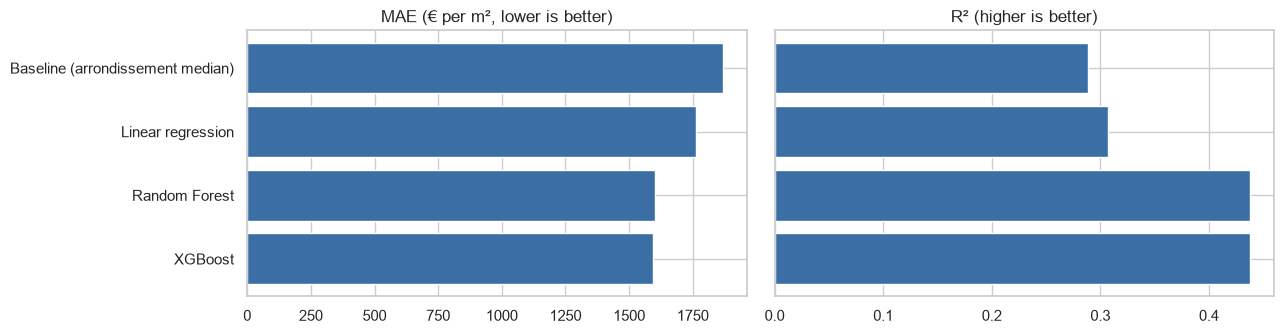

,model,MAE_eur_m2,MAPE_pct,R2
0,Baseline (arrondissement median),1868.0,20.11,0.289
1,Linear regression,1761.0,16.98,0.307
2,Random Forest,1601.0,15.82,0.438
3,XGBoost,1592.0,15.73,0.438


In [2]:
metrics_df = pd.read_csv(PROJECT_ROOT / "reports" / "model_metrics.csv")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].barh(metrics_df["model"], metrics_df["MAE_eur_m2"], color=BLUE)
axes[0].set_title("MAE (€ per m², lower is better)"); axes[0].invert_yaxis()
axes[1].barh(metrics_df["model"], metrics_df["R2"], color=BLUE)
axes[1].set_title("R² (higher is better)"); axes[1].invert_yaxis(); axes[1].set_yticklabels([])
fig.tight_layout(); fig.savefig(FIG_DIR / "model_comparison.png", dpi=150); plt.show()
metrics_df

**Insight:** XGBoost is the best model: MAE 1,592 €/m², MAPE 15.7%, R² 0.438 on the 27,796 sales of the last 12 months. That is 15% lower error than the arrondissement-median baseline (MAE 1,868 €/m², MAPE 20.1%, R² 0.289). Random Forest is almost identical (MAE 1,601), and linear regression sits in between (MAE 1,761): the gain comes from non-linear effects such as the size U-shape and neighbourhood-level location. An R² of 0.44 is realistic, not weak: DVF has no floor, condition, view or energy rating, which explain much of the difference between two flats on the same street.

## 2. Predicted vs actual (XGBoost, test set)

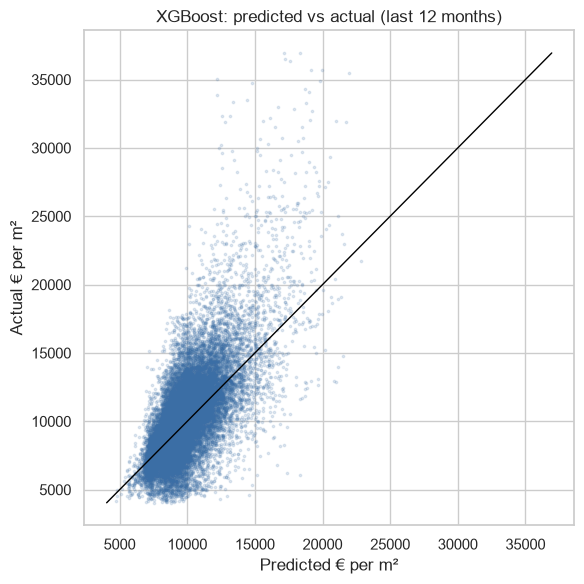

Sales predicted within 10%: 43.6% | within 20%: 73.9%


In [3]:
preds = con.execute("SELECT * FROM model_predictions").df()
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(preds["predicted_price_m2"], preds["actual_price_m2"], s=3, alpha=0.15, color=BLUE)
lims = [preds[["predicted_price_m2", "actual_price_m2"]].min().min(), preds[["predicted_price_m2", "actual_price_m2"]].max().max()]
ax.plot(lims, lims, color="black", linewidth=1)
ax.set_xlabel("Predicted € per m²"); ax.set_ylabel("Actual € per m²")
ax.set_title("XGBoost: predicted vs actual (last 12 months)")
fig.tight_layout(); fig.savefig(FIG_DIR / "predicted_vs_actual.png", dpi=150); plt.show()

err = (preds["predicted_price_m2"] / preds["actual_price_m2"] - 1).abs()
print(f"Sales predicted within 10%: {(err <= 0.10).mean():.1%} | within 20%: {(err <= 0.20).mean():.1%}")

**Insight:** 73.9% of test sales are predicted within 20% of their real price, and 43.6% within 10%. The cloud is centred on the diagonal but wide, and the model compresses extremes: it underestimates the most expensive flats and overestimates the cheapest, which is typical when the missing features (condition, floor, view) drive those extremes.

## 3. SHAP: what drives the prediction?

SHAP splits each prediction into a contribution per feature. Because the model predicts **log** price per m², a SHAP value of +0.10 means roughly **+10%** on the price per m², relative to the average prediction.
Computed on a random sample of 3,000 test sales.

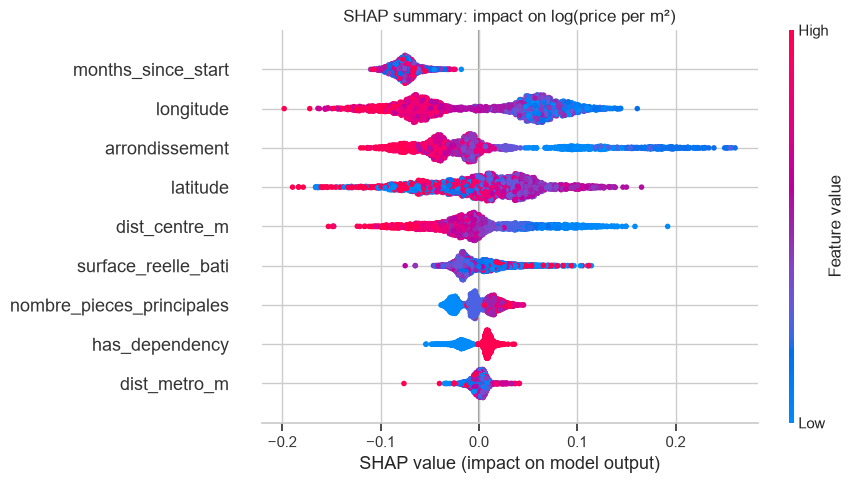

,feature,mean_abs_shap,approx_avg_effect_pct
7,months_since_start,0.075349,7.5
3,longitude,0.065271,6.5
8,arrondissement,0.051731,5.2
2,latitude,0.041013,4.1
5,dist_centre_m,0.034285,3.4
0,surface_reelle_bati,0.018065,1.8
1,nombre_pieces_principales,0.015063,1.5
6,has_dependency,0.012675,1.3
4,dist_metro_m,0.005344,0.5


In [4]:
xgb = XGBRegressor()
xgb.load_model(PROJECT_ROOT / "models" / "xgb_price_m2.json")

X_sample = test[FEATURES].sample(3000, random_state=42) if len(test) > 3000 else test[FEATURES]
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_sample)

shap.plots.beeswarm(sv, max_display=len(FEATURES), show=False)
plt.title("SHAP summary: impact on log(price per m²)")
plt.gcf().savefig(FIG_DIR / "shap_summary.png", dpi=150, bbox_inches="tight"); plt.show()

importance = (pd.DataFrame({"feature": FEATURES, "mean_abs_shap": np.abs(sv.values).mean(axis=0)})
              .sort_values("mean_abs_shap", ascending=False))
importance["approx_avg_effect_pct"] = (100 * importance["mean_abs_shap"]).round(1)
importance.to_csv(PROCESSED_DIR / "agg_shap_importance.csv", index=False)
importance

**Insight:** **Location is the main driver.** Longitude (6.5%), arrondissement (5.2%), latitude (4.1%) and distance to the centre (3.4%) together move the price per m² by about 19% on average. Apartment characteristics come next: surface (1.8%), rooms (1.5%) and a cellar or parking (1.3%). **Time** is the single biggest feature (7.5%): it captures the 2021–2024 market decline. **Distance to the metro is last (0.5%)**, which confirms Phase 5: in Paris almost everyone is close to a station, so it doesn't differentiate prices.

### Dependence plots: surface and distance to metro

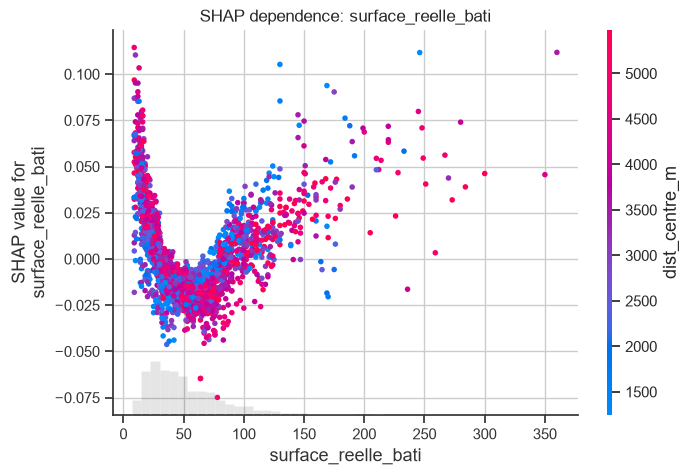

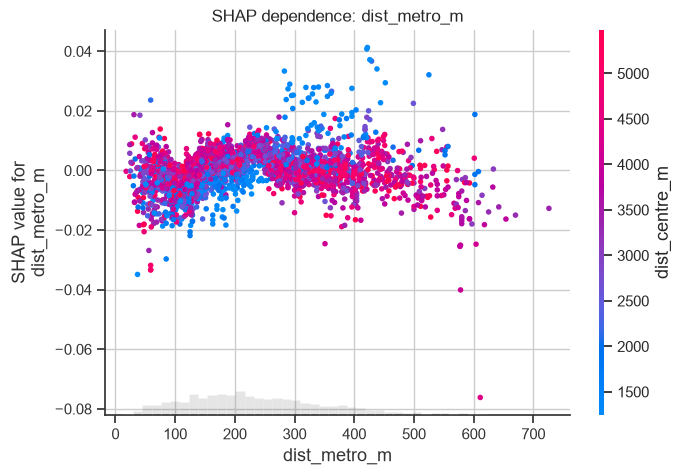

In [5]:
for feature, fname in [("surface_reelle_bati", "shap_dependence_surface.png"),
                       ("dist_metro_m", "shap_dependence_metro.png")]:
    shap.plots.scatter(sv[:, feature], color=sv[:, "dist_centre_m"], show=False)
    plt.title(f"SHAP dependence: {feature}")
    plt.gcf().savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight"); plt.show()

**Insight:** **Surface has a clear U-shape**, matching Q6 in the SQL analysis. Studios under 20 m² get the largest premium (up to +5% to +11%), the effect bottoms out around 50–70 m² (about −2% to −3%), and it rises again above 100 m² (+2% to +5%). The model learned this without being told, which is why trees beat linear regression. **Distance to the metro stays within ±2% across 0–550 m**, with no penalty until about 550 m: proximity is a given in Paris, not a premium.

### Waterfall: one example apartment

A typical sale from the test set: the one whose predicted price is closest to the test-set median.

Arrondissement 18, 29 m², 2 rooms, 128 m from metro
Predicted: 9,499 €/m²  |  Actual: 8,379 €/m²


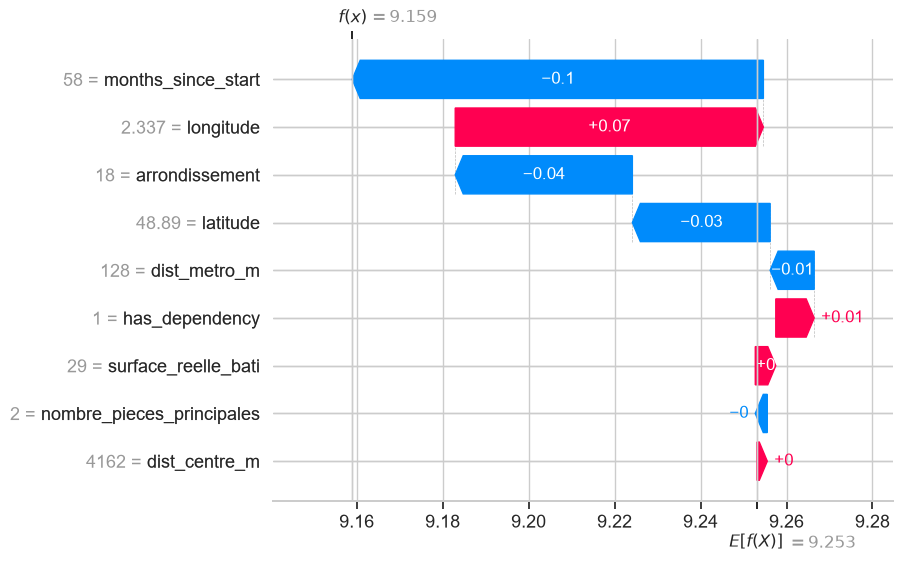

In [6]:
pred_sample = xgb.predict(X_sample)
i = int(np.argmin(np.abs(pred_sample - np.median(pred_sample))))
example = X_sample.iloc[i]
print(f"Arrondissement {example['arrondissement']:.0f}, {example['surface_reelle_bati']:.0f} m², "
      f"{example['nombre_pieces_principales']:.0f} rooms, {example['dist_metro_m']:.0f} m from metro")
print(f"Predicted: {np.exp(pred_sample[i]):,.0f} €/m²  |  Actual: {test.loc[X_sample.index[i], TARGET]:,.0f} €/m²")

shap.plots.waterfall(sv[i], max_display=len(FEATURES), show=False)
plt.gcf().savefig(FIG_DIR / "shap_waterfall_example.png", dpi=150, bbox_inches="tight"); plt.show()

**Insight:** A 29 m², 2-room flat in the 18th, 128 m from a station, sold in late 2025. The model starts from the average prediction (log 9.253 ≈ 10,430 €/m²). Then: the 2025 market level takes it down about 10%, the arrondissement −4% and its northern latitude −3%. Its western position in the 18th, on the Montmartre side, adds +7%, and the cellar +1%. The prediction is 9,499 €/m², against an actual price of 8,379 €/m². The model is 13% too high, possibly because of something DVF doesn't record, such as the floor or the condition of the flat.

## 4. Q8 · Which areas sell below what the model predicts?

For each arrondissement: the median of (actual / predicted − 1) on the test set. Negative means sales happened **below** what comparable flats (same size, location, distances) would predict: a possible sign of under-pricing or of features the model can't see (condition, floor).

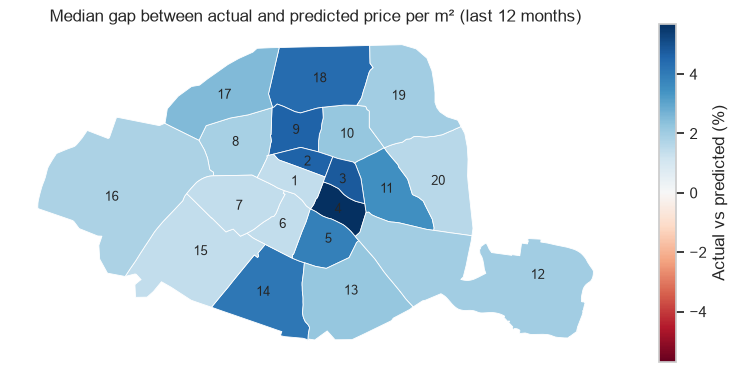

,arrondissement,test_sales,median_actual_m2,median_predicted_m2,median_gap_pct,pct_sales_below_prediction
0,1,251,12111.0,12134.0,1.4,48.2
1,6,715,14224.0,14005.0,1.4,46.2
2,7,869,14111.0,13970.0,1.4,47.2
3,15,2950,9515.0,9451.0,1.4,46.0
4,20,1889,8387.0,8292.0,1.6,46.0
5,16,2280,10952.0,10935.0,1.8,45.9
6,8,617,12105.0,11878.0,1.9,46.7
7,12,1531,9059.0,8883.0,2.0,44.8
8,19,1453,8062.0,7991.0,2.0,44.0
9,10,1363,9355.0,9198.0,2.2,45.7


In [7]:
gap = pd.read_csv(PROCESSED_DIR / "agg_model_gap_by_arr.csv")
arr = gpd.read_file(PROJECT_ROOT / "data" / "external" / "arrondissements.geojson")
cols = {c.lower(): c for c in arr.columns}
arr["arrondissement"] = arr[cols["c_ar"]].astype(int) if "c_ar" in cols else arr[cols["c_arinsee"]].astype(int) - 75100
arr = arr.merge(gap, on="arrondissement").to_crs("EPSG:2154")

lim = arr["median_gap_pct"].abs().max()
fig, ax = plt.subplots(figsize=(8, 6))
arr.plot(column="median_gap_pct", cmap="RdBu", vmin=-lim, vmax=lim, edgecolor="white", linewidth=0.6,
         legend=True, legend_kwds={"label": "Actual vs predicted (%)", "shrink": 0.6}, ax=ax)
for _, r in arr.iterrows():
    p = r.geometry.representative_point()
    ax.annotate(f"{r['arrondissement']}", (p.x, p.y), ha="center", va="center", fontsize=9)
ax.set_axis_off(); ax.set_title("Median gap between actual and predicted price per m² (last 12 months)")
fig.tight_layout(); fig.savefig(FIG_DIR / "map_model_gap.png", dpi=150, bbox_inches="tight"); plt.show()
gap

**Insight:** No arrondissement sold below its prediction: actual medians are 1.4% to 5.7% **above** the model everywhere. The model was trained on 2021–2024 and can't anticipate the 2025 stabilisation, so it slightly underestimates the whole year. The useful signal is relative. The Marais and the centre-north outperformed the model most: the 4th +5.7%, 3rd +4.8%, 9th +4.6%, 2nd +4.6% and 18th +4.4%. Those are the arrondissements that rebounded in 2025 (Q2). The 1st, 6th, 7th and 15th (+1.4%) tracked the model most closely: priced in line with their characteristics, and relatively the best value of 2025 among comparable flats. A next step would be to retrain monthly so the time trend stays current.

## Key takeaways

- **XGBoost beats the baseline by 15%:** MAE 1,592 vs 1,868 €/m², MAPE 15.7% vs 20.1%, R² 0.44 vs 0.29, on a strict time-based test (last 12 months, 27,796 sales).
- **Location drives price** (about 19% average SHAP effect across coordinates, arrondissement and distance to centre), well ahead of size (about 3%) and metro access (0.5%).
- **Size works in a U-shape:** studios and large flats cost more per m² than 50–70 m² flats.
- **The time trend is the biggest single feature**, so a production version should be retrained regularly.
- **Limits:** no floor, condition, balcony or energy rating in DVF, which caps achievable accuracy; the price of a sale includes its cellar or parking.

In [8]:
con.close()